In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from scipy.sparse import load_npz

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
RUTA_PROYECTO = Path("..")

RUTA_VECTORIZACION = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "vectorizacion"
)

RUTA_SVM = (
    RUTA_PROYECTO
    / "models"
    / "segunda_iteracion"
    / "svm"
)

RUTA_SVM.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Vectorización:",
    RUTA_VECTORIZACION.resolve()
)

print(
    "Resultados de SVM:",
    RUTA_SVM.resolve()
)

Vectorización: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\primera_iteracion\vectorizacion
Resultados de SVM: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\segunda_iteracion\svm


In [3]:
X_train_tfidf = load_npz(
    RUTA_VECTORIZACION
    / "X_train_tfidf.npz"
)

X_test_tfidf = load_npz(
    RUTA_VECTORIZACION
    / "X_test_tfidf.npz"
)

y_train = np.load(
    RUTA_VECTORIZACION
    / "y_train.npy",
    allow_pickle=True
)

y_test = np.load(
    RUTA_VECTORIZACION
    / "y_test.npy",
    allow_pickle=True
)

In [4]:
datos_test = pd.read_parquet(
    RUTA_VECTORIZACION
    / "datos_test.parquet"
)

In [5]:
print("COMPROBACIÓN DE LOS DATOS")
print("-------------------------")

print(
    "Matriz de entrenamiento:",
    X_train_tfidf.shape
)

print(
    "Matriz de prueba:",
    X_test_tfidf.shape
)

print(
    "Etiquetas de entrenamiento:",
    len(y_train)
)

print(
    "Etiquetas de prueba:",
    len(y_test)
)

print(
    "¿Coincide entrenamiento?",
    X_train_tfidf.shape[0] == len(y_train)
)

print(
    "¿Coincide prueba?",
    X_test_tfidf.shape[0] == len(y_test)
)

print(
    "¿Mismo número de características?",
    X_train_tfidf.shape[1]
    == X_test_tfidf.shape[1]
)

COMPROBACIÓN DE LOS DATOS
-------------------------
Matriz de entrenamiento: (1188274, 50000)
Matriz de prueba: (297069, 50000)
Etiquetas de entrenamiento: 1188274
Etiquetas de prueba: 297069
¿Coincide entrenamiento? True
¿Coincide prueba? True
¿Mismo número de características? True


In [7]:
modelo_svm = LinearSVC(
    C=1.0,
    class_weight=None,
    tol=1e-4,
    max_iter=2000,
    dual="auto",
    random_state=42
)

In [8]:
# Entrenamiento modelo svm

inicio_entrenamiento = perf_counter()

modelo_svm.fit(
    X_train_tfidf,
    y_train
)

tiempo_entrenamiento_svm = (
    perf_counter() - inicio_entrenamiento
)

print("ENTRENAMIENTO SVM COMPLETADO")
print("---------------------------")

print(
    "Tiempo de entrenamiento:",
    f"{tiempo_entrenamiento_svm:.2f} segundos"
)

print(
    "Iteraciones realizadas:",
    modelo_svm.n_iter_
)

print(
    "¿Convergencia alcanzada?",
    modelo_svm.n_iter_
    < modelo_svm.max_iter
)

ENTRENAMIENTO SVM COMPLETADO
---------------------------
Tiempo de entrenamiento: 1003.28 segundos
Iteraciones realizadas: 303
¿Convergencia alcanzada? True


In [9]:
# Generar predicciones inicio_prediccion = perf_counter()
inicio_prediccion = perf_counter()

predicciones_svm = modelo_svm.predict(
    X_test_tfidf
)

tiempo_prediccion_svm = (
    perf_counter() - inicio_prediccion
)

print("PREDICCIÓN COMPLETADA")
print("---------------------")

print(
    "Reseñas clasificadas:",
    f"{len(predicciones_svm):,}"
)

print(
    "Tiempo de predicción:",
    f"{tiempo_prediccion_svm:.2f} segundos"
)

print(
    "¿Hay una predicción por reseña?",
    len(predicciones_svm) == len(y_test)
)

PREDICCIÓN COMPLETADA
---------------------
Reseñas clasificadas: 297,069
Tiempo de predicción: 0.15 segundos
¿Hay una predicción por reseña? True


In [11]:
# Métricas

accuracy_svm = accuracy_score(
    y_test,
    predicciones_svm
)

precision_macro_svm = precision_score(
    y_test,
    predicciones_svm,
    average="macro",
    zero_division=0
)

recall_macro_svm = recall_score(
    y_test,
    predicciones_svm,
    average="macro",
    zero_division=0
)

f1_macro_svm = f1_score(
    y_test,
    predicciones_svm,
    average="macro",
    zero_division=0
)

print("MÉTRICAS DE SVM")
print("----------------")

print(
    f"Accuracy:        "
    f"{accuracy_svm:.4f}"
)

print(
    f"Precision macro: "
    f"{precision_macro_svm:.4f}"
)

print(
    f"Recall macro:    "
    f"{recall_macro_svm:.4f}"
)

print(
    f"F1 macro:        "
    f"{f1_macro_svm:.4f}"
)

MÉTRICAS DE SVM
----------------
Accuracy:        0.8869
Precision macro: 0.7451
Recall macro:    0.6622
F1 macro:        0.6775


In [12]:
# Informe por clases
informe_svm = classification_report(
    y_test,
    predicciones_svm,
    labels=[
        "negativo",
        "neutral",
        "positivo"
    ],
    digits=4,
    output_dict=True,
    zero_division=0
)

informe_svm_df = (
    pd.DataFrame(informe_svm)
    .transpose()
)

informe_svm_df.round(4)

,precision,recall,f1-score,support
negativo,0.7925,0.8226,0.8073,47697.0000
neutral,0.5232,0.1909,0.2797,23558.0000
positivo,0.9196,0.9731,0.9456,225814.0000
accuracy,0.8869,0.8869,0.8869,0.8869
macro avg,0.7451,0.6622,0.6775,297069.0000
weighted avg,0.8677,0.8869,0.8706,297069.0000


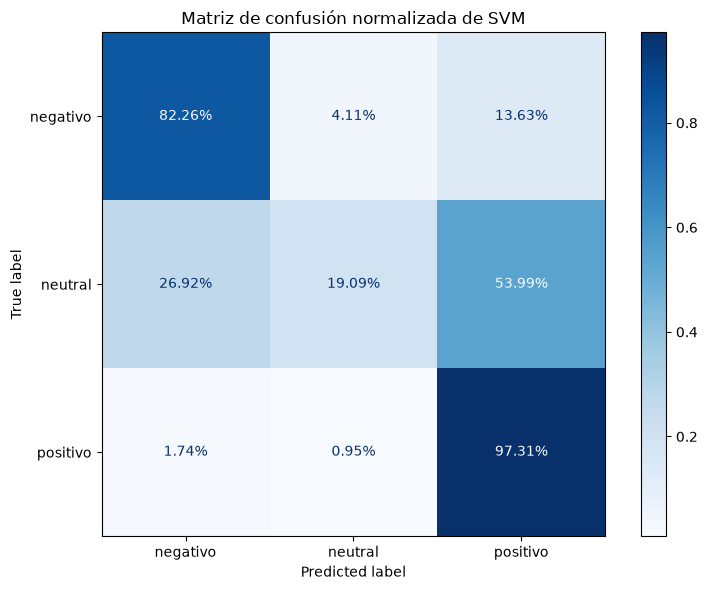

In [13]:
# Matriz de confusión
orden_clases = [
    "negativo",
    "neutral",
    "positivo"
]

figura, eje = plt.subplots(
    figsize=(8, 6)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_svm,
    labels=orden_clases,
    normalize="true",
    cmap="Blues",
    values_format=".2%",
    ax=eje
)

eje.set_title(
    "Matriz de confusión normalizada de SVM"
)

figura.tight_layout()
plt.show()

In [14]:
RUTA_SVM.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    modelo_svm,
    RUTA_SVM / "modelo_svm.joblib"
)

np.save(
    RUTA_SVM / "predicciones_svm.npy",
    predicciones_svm
)

metricas_svm = {
    "modelo": "LinearSVC",
    "C": float(modelo_svm.C),
    "class_weight": modelo_svm.class_weight,
    "tol": float(modelo_svm.tol),
    "max_iter": int(modelo_svm.max_iter),
    "iteraciones_realizadas": int(modelo_svm.n_iter_),
    "convergencia_alcanzada": bool(
        modelo_svm.n_iter_ < modelo_svm.max_iter
    ),
    "accuracy": float(accuracy_svm),
    "precision_macro": float(precision_macro_svm),
    "recall_macro": float(recall_macro_svm),
    "f1_macro": float(f1_macro_svm),
    "tiempo_entrenamiento_segundos": float(
        tiempo_entrenamiento_svm
    ),
    "tiempo_prediccion_segundos": float(
        tiempo_prediccion_svm
    ),
    "numero_resenas_entrenamiento": int(
        len(y_train)
    ),
    "numero_resenas_prueba": int(
        len(y_test)
    ),
    "numero_caracteristicas": int(
        X_train_tfidf.shape[1]
    )
}

with open(
    RUTA_SVM / "metricas_svm.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_svm,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Modelo, predicciones y métricas guardados.")

Modelo, predicciones y métricas guardados.


In [15]:
informe_svm_df.to_csv(
    RUTA_SVM / "informe_clasificacion_svm.csv"
)

In [16]:
# Optimizar el svm

from sklearn.model_selection import train_test_split

(
    X_train_interno_svm,
    X_validacion_svm,
    y_train_interno_svm,
    y_validacion_svm
) = train_test_split(
    X_train_tfidf,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [17]:
print("DIVISIÓN INTERNA PARA SVM")
print("-------------------------")

print(
    "Entrenamiento interno:",
    X_train_interno_svm.shape
)

print(
    "Validación:",
    X_validacion_svm.shape
)

print(
    "Etiquetas de entrenamiento:",
    len(y_train_interno_svm)
)

print(
    "Etiquetas de validación:",
    len(y_validacion_svm)
)

print(
    "¿Coincide entrenamiento?",
    X_train_interno_svm.shape[0]
    == len(y_train_interno_svm)
)

print(
    "¿Coincide validación?",
    X_validacion_svm.shape[0]
    == len(y_validacion_svm)
)

DIVISIÓN INTERNA PARA SVM
-------------------------
Entrenamiento interno: (950619, 50000)
Validación: (237655, 50000)
Etiquetas de entrenamiento: 950619
Etiquetas de validación: 237655
¿Coincide entrenamiento? True
¿Coincide validación? True


In [18]:
# Configuraciones como las de RL

configuraciones_svm = [
    {
        "nombre": "regularizacion_fuerte",
        "C": 0.1,
        "class_weight": None
    },
    {
        "nombre": "regularizacion_intermedia",
        "C": 0.5,
        "class_weight": None
    },
    {
        "nombre": "clases_balanceadas",
        "C": 0.5,
        "class_weight": "balanced"
    }
]

In [19]:
import gc
import pandas as pd

from time import perf_counter

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

resultados_ajuste_svm = []
informes_ajuste_svm = {}

for numero, configuracion in enumerate(
    configuraciones_svm,
    start=1
):
    print(
        f"\nCONFIGURACIÓN {numero}/"
        f"{len(configuraciones_svm)}"
    )
    print(configuracion["nombre"])
    print("-" * 50)

    modelo_temporal = LinearSVC(
        C=configuracion["C"],
        class_weight=configuracion["class_weight"],
        tol=1e-3,
        max_iter=1000,
        dual="auto",
        random_state=42
    )

    print("Entrenando modelo...")

    inicio_entrenamiento = perf_counter()

    modelo_temporal.fit(
        X_train_interno_svm,
        y_train_interno_svm
    )

    tiempo_entrenamiento = (
        perf_counter() - inicio_entrenamiento
    )

    print("Generando predicciones...")

    inicio_prediccion = perf_counter()

    predicciones_validacion = (
        modelo_temporal.predict(
            X_validacion_svm
        )
    )

    tiempo_prediccion = (
        perf_counter() - inicio_prediccion
    )

    accuracy = accuracy_score(
        y_validacion_svm,
        predicciones_validacion
    )

    precision_macro = precision_score(
        y_validacion_svm,
        predicciones_validacion,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_validacion_svm,
        predicciones_validacion,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_validacion_svm,
        predicciones_validacion,
        average="macro",
        zero_division=0
    )

    informe = classification_report(
        y_validacion_svm,
        predicciones_validacion,
        labels=[
            "negativo",
            "neutral",
            "positivo"
        ],
        output_dict=True,
        zero_division=0
    )

    informes_ajuste_svm[
        configuracion["nombre"]
    ] = informe

    iteraciones = int(
        modelo_temporal.n_iter_
    )

    convergencia = (
        iteraciones
        < modelo_temporal.max_iter
    )

    resultados_ajuste_svm.append({
        "Configuración": configuracion["nombre"],
        "C": configuracion["C"],
        "class_weight": str(
            configuracion["class_weight"]
        ),
        "tol": modelo_temporal.tol,
        "max_iter": modelo_temporal.max_iter,
        "Iteraciones": iteraciones,
        "Convergencia": convergencia,
        "Accuracy": accuracy,
        "Precision macro": precision_macro,
        "Recall macro": recall_macro,
        "F1 macro": f1_macro,
        "F1 negativo": informe[
            "negativo"
        ]["f1-score"],
        "F1 neutral": informe[
            "neutral"
        ]["f1-score"],
        "F1 positivo": informe[
            "positivo"
        ]["f1-score"],
        "Tiempo entrenamiento": (
            tiempo_entrenamiento
        ),
        "Tiempo predicción": (
            tiempo_prediccion
        )
    })

    print("\nRESULTADOS")
    print("----------")
    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Precision macro: {precision_macro:.4f}")
    print(f"Recall macro:    {recall_macro:.4f}")
    print(f"F1 macro:        {f1_macro:.4f}")

    print(
        "F1 negativo:",
        f"{informe['negativo']['f1-score']:.4f}"
    )

    print(
        "F1 neutral:",
        f"{informe['neutral']['f1-score']:.4f}"
    )

    print(
        "F1 positivo:",
        f"{informe['positivo']['f1-score']:.4f}"
    )

    print("Iteraciones:", iteraciones)
    print("Convergencia:", convergencia)

    print(
        "Tiempo de entrenamiento:",
        f"{tiempo_entrenamiento / 60:.2f} minutos"
    )

    print(
        "Tiempo de predicción:",
        f"{tiempo_prediccion:.2f} segundos"
    )

    del modelo_temporal
    del predicciones_validacion

    gc.collect()


CONFIGURACIÓN 1/3
regularizacion_fuerte
--------------------------------------------------
Entrenando modelo...
Generando predicciones...

RESULTADOS
----------
Accuracy:        0.8875
Precision macro: 0.7646
Recall macro:    0.6481
F1 macro:        0.6615
F1 negativo: 0.8089
F1 neutral: 0.2305
F1 positivo: 0.9450
Iteraciones: 74
Convergencia: True
Tiempo de entrenamiento: 3.07 minutos
Tiempo de predicción: 0.09 segundos

CONFIGURACIÓN 2/3
regularizacion_intermedia
--------------------------------------------------
Entrenando modelo...
Generando predicciones...

RESULTADOS
----------
Accuracy:        0.8879
Precision macro: 0.7542
Recall macro:    0.6586
F1 macro:        0.6741
F1 negativo: 0.8082
F1 neutral: 0.2683
F1 positivo: 0.9459
Iteraciones: 200
Convergencia: True
Tiempo de entrenamiento: 8.32 minutos
Tiempo de predicción: 0.27 segundos

CONFIGURACIÓN 3/3
clases_balanceadas
--------------------------------------------------
Entrenando modelo...
Generando predicciones...

RESULT

In [20]:
resultados_ajuste_svm_df = pd.DataFrame(
    resultados_ajuste_svm
)

resultados_ajuste_svm_df = (
    resultados_ajuste_svm_df
    .sort_values(
        by="F1 macro",
        ascending=False
    )
    .reset_index(drop=True)
)

resultados_ajuste_svm_df.round(4)

,Configuración,C,class_weight,tol,max_iter,Iteraciones,Convergencia,Accuracy,Precision macro,Recall macro,F1 macro,F1 negativo,F1 neutral,F1 positivo,Tiempo entrenamiento,Tiempo predicción
0,clases_balanceadas,0.5,balanced,0.001,1000,152,True,0.8725,0.7038,0.7215,0.7122,0.7931,0.4022,0.9414,465.8053,0.2264
1,regularizacion_intermedia,0.5,None,0.001,1000,200,True,0.8879,0.7542,0.6586,0.6741,0.8082,0.2683,0.9459,499.1834,0.2660
2,regularizacion_fuerte,0.1,None,0.001,1000,74,True,0.8875,0.7646,0.6481,0.6615,0.8089,0.2305,0.9450,183.9153,0.0857


In [21]:
mejor_configuracion_svm = (
    resultados_ajuste_svm_df.iloc[0]
)

print("MEJOR CONFIGURACIÓN SVM")
print("-----------------------")

print(
    "Configuración:",
    mejor_configuracion_svm["Configuración"]
)

print(
    "F1 macro:",
    f"{mejor_configuracion_svm['F1 macro']:.4f}"
)

print(
    "Accuracy:",
    f"{mejor_configuracion_svm['Accuracy']:.4f}"
)

print(
    "F1 negativo:",
    f"{mejor_configuracion_svm['F1 negativo']:.4f}"
)

print(
    "F1 neutral:",
    f"{mejor_configuracion_svm['F1 neutral']:.4f}"
)

print(
    "F1 positivo:",
    f"{mejor_configuracion_svm['F1 positivo']:.4f}"
)

print(
    "Convergencia:",
    mejor_configuracion_svm["Convergencia"]
)

MEJOR CONFIGURACIÓN SVM
-----------------------
Configuración: clases_balanceadas
F1 macro: 0.7122
Accuracy: 0.8725
F1 negativo: 0.7931
F1 neutral: 0.4022
F1 positivo: 0.9414
Convergencia: True


In [22]:
RUTA_OPTIMIZACION_SVM = (
    RUTA_SVM
    / "optimizacion"
)

RUTA_OPTIMIZACION_SVM.mkdir(
    parents=True,
    exist_ok=True
)

resultados_ajuste_svm_df.to_csv(
    RUTA_OPTIMIZACION_SVM
    / "comparacion_configuraciones_svm.csv",
    index=False
)

print(
    "Comparación guardada en:",
    RUTA_OPTIMIZACION_SVM.resolve()
)

Comparación guardada en: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\segunda_iteracion\svm\optimizacion


In [23]:
# Entrenamiento final

modelo_svm_optimizado = LinearSVC(
    C=0.5,
    class_weight="balanced",
    tol=1e-3,
    max_iter=1000,
    dual="auto",
    random_state=42
)

inicio_entrenamiento = perf_counter()

modelo_svm_optimizado.fit(
    X_train_tfidf,
    y_train
)

tiempo_entrenamiento_svm_optimizado = (
    perf_counter() - inicio_entrenamiento
)

iteraciones_svm_optimizado = int(
    modelo_svm_optimizado.n_iter_
)

convergencia_svm_optimizado = (
    iteraciones_svm_optimizado
    < modelo_svm_optimizado.max_iter
)

print("ENTRENAMIENTO SVM OPTIMIZADO")
print("----------------------------")
print(
    "Tiempo:",
    f"{tiempo_entrenamiento_svm_optimizado:.2f} segundos"
)
print(
    "Iteraciones:",
    iteraciones_svm_optimizado
)
print(
    "¿Convergencia alcanzada?",
    convergencia_svm_optimizado
)



ENTRENAMIENTO SVM OPTIMIZADO
----------------------------
Tiempo: 928.40 segundos
Iteraciones: 226
¿Convergencia alcanzada? True


In [24]:
inicio_prediccion = perf_counter()

predicciones_svm_optimizado = (
    modelo_svm_optimizado.predict(
        X_test_tfidf
    )
)

tiempo_prediccion_svm_optimizado = (
    perf_counter() - inicio_prediccion
)

print("\nPREDICCIÓN COMPLETADA")
print("---------------------")
print(
    "Reseñas clasificadas:",
    f"{len(predicciones_svm_optimizado):,}"
)
print(
    "Tiempo de predicción:",
    f"{tiempo_prediccion_svm_optimizado:.2f} segundos"
)
print(
    "¿Hay una predicción por reseña?",
    len(predicciones_svm_optimizado)
    == len(y_test)
)


PREDICCIÓN COMPLETADA
---------------------
Reseñas clasificadas: 297,069
Tiempo de predicción: 0.66 segundos
¿Hay una predicción por reseña? True


In [25]:
accuracy_svm_optimizado = accuracy_score(
    y_test,
    predicciones_svm_optimizado
)

precision_macro_svm_optimizado = precision_score(
    y_test,
    predicciones_svm_optimizado,
    average="macro",
    zero_division=0
)

recall_macro_svm_optimizado = recall_score(
    y_test,
    predicciones_svm_optimizado,
    average="macro",
    zero_division=0
)

f1_macro_svm_optimizado = f1_score(
    y_test,
    predicciones_svm_optimizado,
    average="macro",
    zero_division=0
)

print("\nMÉTRICAS DE SVM OPTIMIZADO")
print("--------------------------")
print(
    f"Exactitud:          "
    f"{accuracy_svm_optimizado:.4f}"
)
print(
    f"Precisión macro:    "
    f"{precision_macro_svm_optimizado:.4f}"
)
print(
    f"Exhaustividad macro:"
    f" {recall_macro_svm_optimizado:.4f}"
)
print(
    f"F1 macro:           "
    f"{f1_macro_svm_optimizado:.4f}"
)


MÉTRICAS DE SVM OPTIMIZADO
--------------------------
Exactitud:          0.8741
Precisión macro:    0.7082
Exhaustividad macro: 0.7272
F1 macro:           0.7172


In [26]:
informe_svm_optimizado = classification_report(
    y_test,
    predicciones_svm_optimizado,
    labels=[
        "negativo",
        "neutral",
        "positivo"
    ],
    digits=4,
    output_dict=True,
    zero_division=0
)

informe_svm_optimizado_df = (
    pd.DataFrame(
        informe_svm_optimizado
    )
    .transpose()
)

informe_svm_optimizado_df.round(4)

,precision,recall,f1-score,support
negativo,0.7773,0.8193,0.7978,47697.0000
neutral,0.3956,0.4302,0.4122,23558.0000
positivo,0.9516,0.9320,0.9417,225814.0000
accuracy,0.8741,0.8741,0.8741,0.8741
macro avg,0.7082,0.7272,0.7172,297069.0000
weighted avg,0.8795,0.8741,0.8766,297069.0000


In [27]:
# Comparación

comparacion_svm = pd.DataFrame([
    {
        "Modelo": "SVM inicial",
        "Exactitud": accuracy_svm,
        "Precisión macro": precision_macro_svm,
        "Exhaustividad macro": recall_macro_svm,
        "F1 macro": f1_macro_svm,
        "Tiempo entrenamiento": tiempo_entrenamiento_svm,
        "Iteraciones": int(modelo_svm.n_iter_),
        "Convergencia": (
            modelo_svm.n_iter_
            < modelo_svm.max_iter
        )
    },
    {
        "Modelo": "SVM optimizado",
        "Exactitud": accuracy_svm_optimizado,
        "Precisión macro": (
            precision_macro_svm_optimizado
        ),
        "Exhaustividad macro": (
            recall_macro_svm_optimizado
        ),
        "F1 macro": f1_macro_svm_optimizado,
        "Tiempo entrenamiento": (
            tiempo_entrenamiento_svm_optimizado
        ),
        "Iteraciones": (
            iteraciones_svm_optimizado
        ),
        "Convergencia": (
            convergencia_svm_optimizado
        )
    }
])

comparacion_svm.round(4)

,Modelo,Exactitud,Precisión macro,Exhaustividad macro,F1 macro,Tiempo entrenamiento,Iteraciones,Convergencia
0,SVM inicial,0.8869,0.7451,0.6622,0.6775,1003.2829,303,True
1,SVM optimizado,0.8741,0.7082,0.7272,0.7172,928.3951,226,True


In [28]:
# Guardar modelo optimizado

RUTA_SVM_OPTIMIZADO = (
    RUTA_SVM
    / "modelo_optimizado"
)

RUTA_SVM_OPTIMIZADO.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    modelo_svm_optimizado,
    RUTA_SVM_OPTIMIZADO
    / "modelo_svm_optimizado.joblib"
)

np.save(
    RUTA_SVM_OPTIMIZADO
    / "predicciones_svm_optimizado.npy",
    predicciones_svm_optimizado
)

metricas_svm_optimizado = {
    "modelo": "SVM optimizado",
    "implementacion": "LinearSVC",
    "C": 0.5,
    "class_weight": "balanced",
    "tol": 1e-3,
    "max_iter": 1000,
    "iteraciones_realizadas": int(
        iteraciones_svm_optimizado
    ),
    "convergencia_alcanzada": bool(
        convergencia_svm_optimizado
    ),
    "exactitud": float(
        accuracy_svm_optimizado
    ),
    "precision_macro": float(
        precision_macro_svm_optimizado
    ),
    "exhaustividad_macro": float(
        recall_macro_svm_optimizado
    ),
    "f1_macro": float(
        f1_macro_svm_optimizado
    ),
    "tiempo_entrenamiento_segundos": float(
        tiempo_entrenamiento_svm_optimizado
    ),
    "tiempo_prediccion_segundos": float(
        tiempo_prediccion_svm_optimizado
    ),
    "numero_resenas_entrenamiento": int(
        len(y_train)
    ),
    "numero_resenas_prueba": int(
        len(y_test)
    ),
    "numero_caracteristicas": int(
        X_train_tfidf.shape[1]
    )
}

with open(
    RUTA_SVM_OPTIMIZADO
    / "metricas_svm_optimizado.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_svm_optimizado,
        archivo,
        indent=4,
        ensure_ascii=False
    )

informe_svm_optimizado_df.to_csv(
    RUTA_SVM_OPTIMIZADO
    / "informe_clasificacion_svm_optimizado.csv"
)

print("SVM optimizado guardado correctamente.")

SVM optimizado guardado correctamente.
